# Degradation of an electrolysis single repeating unit + EIS

In this tutorial, we model the Galvanostatic case of Ref. [1] (Fig. 6), including three degradation phenomena:

* **Ni agglomeration**: Ni particles in the fuel electrode coarsen, reducing the triple phase boundary (TPB) length and increasing the polarization resistance.
* **Ni migration**: Ni moves away from the fuel electrode/electrolyte interface, leaving a Ni-depleted zone that conducts only ions and increases the ohmic resistance.
* **Interconnect oxidation**: an oxide scale grows on the interconnect, increasing the ohmic resistance.

The Ni migration model can also switch to a second rate once a threshold is reached. As an illustration, we use the cathodic overpotential threshold (COT) and the faster Ni migration rates of Ref. [2]; the simulation itself uses the rates of Ref. [1].

**Temperature:** Ref. [1] solves an adiabatic energy balance along the cell: the heat released when the voltage exceeds the thermoneutral voltage raises the temperature, which lowers the resistances. nest-soc's `Cell` has the same option (`energy_balance=True`); without it, the cell is isothermal. We run both.

**References**
1. J. Beyrami et al., *Degradation modeling in solid oxide electrolysis systems: A comparative analysis of operation modes*, Energy Convers. Manag. X 23 (2024) 100653. https://doi.org/10.1016/j.ecmx.2024.100653
2. J. Beyrami et al., *Lifetime and performance of solid oxide electrolysis stacks and systems under different operation modes and conditions*, Int. J. Hydrogen Energy 102 (2025) 980-995. https://doi.org/10.1016/j.ijhydene.2025.01.028

## 1. Imports

In [79]:
from time import process_time

import matplotlib.pyplot as plt
import numpy as np

from nest import boundary, cell, degradation, layers, properties
from nest.constants import F

## 2. Degradation models

### 2.1. Ni agglomeration

In [80]:
EPSILON = 0.3
TAU = 1.23 * (1 - EPSILON) ** (4 / 3) / EPSILON

ni_agglomeration = degradation.NickelAgglomeration(
    psi_ed=0.4,  # Ni volume fraction [-]
    psi_el=0.6,  # YSZ volume fraction [-]
    r0_ed=0.3e-6,  # Initial Ni particle radius [m]
    r0_el=0.265e-6,  # YSZ particle radius [m]
    epsilon=EPSILON,
    alpha=4.5907e9,  # Fitted rate prefactor
    r_ed_max=0.35639e-6,  # Fitted maximum Ni radius [m]
    theta=15 * np.pi / 180,  # Ni/YSZ contact angle [rad]
)
# TPB length at the beginning of life, used to normalize the exchange current
tpb_0 = ni_agglomeration.pol_deg(ni_agglomeration.m0)

### 2.2. Ni migration

The `NickelMigration` model takes a growth rate of the Ni-depleted zone thickness, $d\delta/dt = f(T, j, \eta)$, and optionally a threshold condition with a second rate.

In Ref. [1], the rate is a fit to measured ohmic-resistance increase rates (750-800 °C, 0.75-1 A/cm²):

$$\frac{d\delta_{Ni,mi}}{dt} = c_1 T + c_2 j + c_3 T j + c_4$$

It depends on $T$ and $j$ only. Ref. [2] gives a second set of coefficients for after the COT:

$$\eta_{COT} = c_1 \exp(c_2 / T)$$

**Note:** both rate fits are based on measurements at 750-800 °C and 0.75-1 A/cm². Outside this range they are extrapolations; for example, above ~800 °C the rate after the COT can become lower than the rate before it, or zero.

In [81]:
# (c1, c2, c3, c4): before (Ref. [1], Table 6) and after the COT (Ref. [2], Table 2)
COEFFICIENTS_BEFORE = (-1.30122701e-11, -1.45805429e-12, 1.54380637e-15, 1.28698565e-08)
COEFFICIENTS_AFTER = (-2.38323024e-11, 6.04787252e-12, -4.84902225e-15, 1.96404033e-08)


def fitted_rate(coefficients, T, j, j_min):
    # Zero up to j_min, linear up to 0.75 A/cm^2, [m/h]
    c1, c2, c3, c4 = coefficients
    j = abs(j)
    if j <= j_min:
        return 0.0
    j_fit = max(j, 7500.0)
    rate = c1 * T + c2 * j_fit + c3 * T * j_fit + c4
    if j < 7500.0:
        rate *= (j - j_min) / (7500.0 - j_min)
    return max(rate, 0.0)


def rate_before_threshold(T, j, eta):
    return fitted_rate(COEFFICIENTS_BEFORE, T, j, 3000.0)


def rate_after_threshold(T, j, eta):
    return fitted_rate(COEFFICIENTS_AFTER, T, j, 2000.0)


def critical_overpotential(T):
    # Cathodic overpotential threshold (COT) [V]
    return 4.05338e-5 * np.exp(9.15250e3 / T)


def overpotential_threshold(T, j, eta):
    # Threshold reached when the fuel electrode overpotential exceeds the COT
    return abs(eta) >= critical_overpotential(T)

#### Two rates with a threshold

In [82]:
two_rate_model = degradation.NickelMigration(
    rate=rate_before_threshold,
    threshold=overpotential_threshold,
    rate_after_threshold=rate_after_threshold,
)
state = boundary.BoundaryData(T=750 + 273.15, j=-0.76e4)

The Ni-depleted zone is represented as its own layer in the electrolyte stack. It starts with zero thickness and the model adds the depleted thickness to it. Its conductivity is that of the porous YSZ left behind by the Ni (Ref. [1], Eqs. (38)-(39)):

$$\sigma = \frac{\epsilon}{\tau} \frac{\sigma_0}{T} \exp\left(-\frac{E_a}{RT}\right)$$

### 2.3. Interconnect oxidation

The oxide scale grows parabolically (Wagner's theory) and has its own conductivity (Ref. [1], Eqs. (41)-(43), Table 7):

$$\frac{dh^2}{dt} = k_{mg} \exp\left(-\frac{E_{a,ox}}{RT}\right), \qquad \sigma_{ox} = k_{ox} \exp\left(-\frac{E_{el}}{RT}\right)$$

## 3. Cell definition

The single repeating unit of Ref. [1] (Tables 1 and 3):

* Fuel electrode (support + functional layer, 310 µm). Its exchange current is scaled by the TPB length of the Ni agglomeration model, so the pre-exponential factor is divided by its initial value.
* Air electrode (LSCF/CGO + CGO barrier, 36 µm).
* Electrolyte layers: Ni-depleted zone + lumped ohmic resistance $\frac{T}{B}\exp\left(\frac{E}{RT}\right)$ (Ref. [1], Eq. (22)) + interconnect oxide scale.

The lumped ohmic resistance uses $B$ and $E$ of Ref. [1], Table 3.

With `energy_balance=True`, the temperature of each element follows from an adiabatic energy balance: the heat released, $jA(V - V_{tn})$, heats the fuel and air flows, $\Delta T = jA(V_{tn} - V)/\sum \dot{n}_i c_{p,i}$.

In [83]:
AREA = 0.20 * 0.20  # Active area [m^2]

fuel_mix = properties.Mixture((properties.BasicSpecies.H2, properties.BasicSpecies.H2O))
air_mix = properties.Mixture((properties.BasicSpecies.O2, properties.BasicSpecies.N2))


def make_cell(energy_balance=False, elements=20):
    fuel = layers.Layer(
        delta=310e-6,
        kinetic=layers.ButlerVolmer(
            fuel_mix,
            nu=[-1, 1],
            n_e=2,
            alpha=0.782,
            beta=1 - 0.782,
            gamma=8.546e6 / tpb_0,
            p=[-0.0467, 0.3905],
            theta=1,
            E_act=1.26e5,
        ),
        transport=layers.PorousTransport(dp=6.41e-7, epsilon=EPSILON, tau=TAU),
        degradation=ni_agglomeration,
    )
    air = layers.Layer(
        delta=36e-6,
        kinetic=layers.ButlerVolmer(
            air_mix,
            nu=[-0.5, 0.0],
            n_e=2,
            alpha=0.996,
            beta=1 - 0.996,
            gamma=2.593e8,
            p=[0.146, 0.0],
            theta=1,
            E_act=1.22e5,
        ),
        transport=layers.PorousTransport(dp=3.04e-7, epsilon=EPSILON, tau=TAU),
    )
    # delta=1 m and sigma0=B give an area-specific resistance T/B*exp(E/RT) [ohm m^2]
    ohmic = layers.Layer(
        delta=1.0,
        conductivity=layers.Conductivity(sigma0=7.8247e11, E_act=8.0022e4, theta=-1),
    )
    # Ni-depleted zone and interconnect oxide scale: start with zero thickness and grow
    Ni_depleted = layers.Layer(
        delta=0.0,
        conductivity=layers.Conductivity(
            sigma0=3.6e7 * EPSILON / TAU, E_act=8e4, theta=-1
        ),
        degradation=degradation.NickelMigration(rate=rate_before_threshold),  # Ref. [1]
    )
    oxide_scale = layers.Layer(
        delta=0.0,
        conductivity=layers.Conductivity(sigma0=45.8, E_act=33.3e3, theta=0),
        degradation=degradation.InterconnectOxidation(k_mg=0.0236, E_ox=260e3),
    )
    electrolyte = (Ni_depleted, ohmic, oxide_scale)
    return cell.Cell(
        AREA, fuel, electrolyte, air, elements=elements, energy_balance=energy_balance
    )

## 4. Operating conditions

Galvanostatic operation at 0.76 A/cm² with an inlet temperature of 750 °C, with 10 % H₂ + 90 % H₂O at 70 % steam utilization and an oxygen-to-steam ratio of 1 with air (Ref. [1], Table 8). The inlet flows follow from the current density.

In [84]:
def inlet_conditions(T, j, utilization=0.7, x_H2=0.1, oxygen_to_steam=1.0):
    n_H2O = AREA * abs(j) / (2 * F) / utilization  # [mol/s]
    n_H2 = x_H2 / (1 - x_H2) * n_H2O
    n_O2 = oxygen_to_steam * n_H2O
    n_N2 = 0.79 / 0.21 * n_O2
    return boundary.BoundaryData(
        V=1.3,
        j=j,
        n_fuel=np.array([n_H2, n_H2O]),
        n_air=np.array([n_O2, n_N2]),
        T=T,
        P=101325,
    )


T = 750 + 273.15  # Inlet temperature [K]
j = -0.76e4  # [A/m^2], negative in electrolysis
t_max = 25000  # [h]

### 4.1. Beginning of life

In [85]:
cell_model = make_cell(energy_balance=True)
n = cell_model.elements
y0 = np.concatenate([np.full(n, ni_agglomeration.m0), np.zeros(2 * n), [0]])
steady = cell_model.solve_time_step(y0, inlet_conditions(T, j), "current")

index = 4 + 2 + 2  # Row of the fuel electrode overpotential in the solution
print(f"Beginning-of-life voltage: {np.mean(steady[0]):.4f} V")
print(f"Average current density: {np.mean(steady[1]) / 1e4:.2f} A/cm^2")
print(
    f"Current density along the cell: {steady[1].min() / 1e4:.2f} to {steady[1].max() / 1e4:.2f} A/cm^2"
)
print(f"Outlet temperature: {steady[2][-1] - 273.15:.1f} °C")
print(f"Average fuel electrode overpotential: {np.mean(np.abs(steady[index])):.3f} V")

Beginning-of-life voltage: 1.2861 V
Average current density: -0.76 A/cm^2
Current density along the cell: -1.09 to -0.53 A/cm^2
Outlet temperature: 750.6 °C
Average fuel electrode overpotential: 0.218 V


## 5. Degradation simulation

In [86]:
def simulate(energy_balance):
    cell_model = make_cell(energy_balance)
    start_time = process_time()
    solution = cell_model.solve_for_time(inlet_conditions(T, j), "current", t_max)
    computation_time = process_time() - start_time

    radius = solution.y[:n]
    depleted = solution.y[n : 3 * n : 2]
    oxide = np.sqrt(solution.y[n + 1 : 3 * n : 2])
    Ni_depleted, oxide_scale = cell_model.electrolyte[0], cell_model.electrolyte[2]

    conditions = inlet_conditions(T, j)
    voltage, eta_fuel, T_out, T_mean, asr_ni, asr_ox = [], [], [], [], [], []
    for k, y in enumerate(solution.y.T):
        steady = cell_model.solve_time_step(y, conditions, "current")
        T_local = steady[2]
        voltage.append(np.mean(steady[0]))
        eta_fuel.append(np.max(np.abs(steady[index])))
        T_out.append(T_local[-1])
        T_mean.append(np.mean(T_local))
        asr_ni.append(np.mean(depleted[:, k] / Ni_depleted.conductivity.sigma(T_local)))
        asr_ox.append(np.mean(oxide[:, k] / oxide_scale.conductivity.sigma(T_local)))
        conditions.V = voltage[-1]

    tpb_ratio = np.array(
        [[ni_agglomeration.pol_deg(r) / tpb_0 for r in rs] for rs in radius.T]
    ).mean(axis=1)
    result = dict(
        t=solution.t / 1000,  # [kh]
        voltage=np.array(voltage),
        eta_fuel=np.array(eta_fuel),
        T_out=np.array(T_out),
        T_mean=np.array(T_mean),
        asr_ni=np.array(asr_ni),
        asr_ox=np.array(asr_ox),
        tpb_ratio=tpb_ratio,
        depleted=depleted.mean(axis=0),  # Ni-depleted zone thickness [m]
        oxide=oxide.mean(axis=0),  # Oxide scale thickness [m]
    )
    print(
        f"Computation time: {computation_time:.1f} s): after {t_max} h, "
        f"voltage {voltage[-1]:.3f} V, outlet {T_out[-1] - 273.15:.0f} °C, "
        f"ASR Ni migration {asr_ni[-1] * 1e7:.0f} mOhm cm2, interconnect oxidation {asr_ox[-1] * 1e7:.0f} mOhm cm2"
    )
    return result


adiabatic = simulate(energy_balance=True)

Computation time: 4.3 s): after 25000 h, voltage 1.463 V, outlet 864 °C, ASR Ni migration 217 mOhm cm2, interconnect oxidation 94 mOhm cm2


## 6. Results

### 6.1. Degradation phenomena

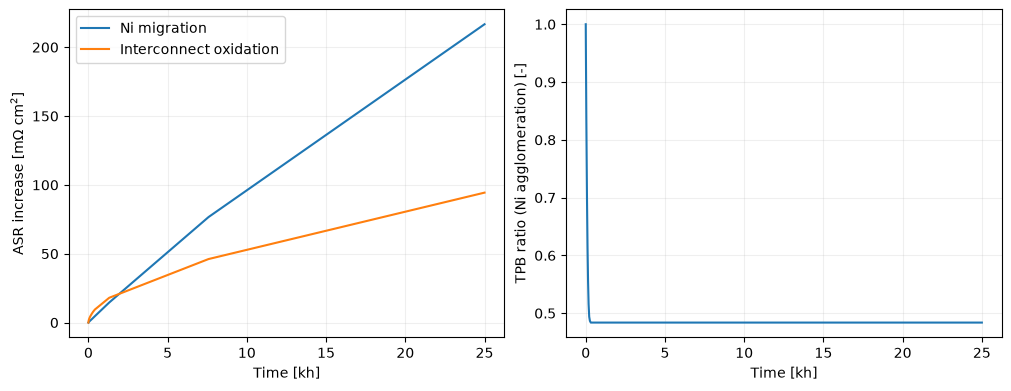

In [87]:
r = adiabatic
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
axes[0].plot(r["t"], r["asr_ni"] * 1e7, label="Ni migration")
axes[0].plot(r["t"], r["asr_ox"] * 1e7, label="Interconnect oxidation")
axes[0].set(ylabel=r"ASR increase [m$\Omega$ cm$^2$]")
axes[0].legend()
axes[1].plot(r["t"], r["tpb_ratio"])
axes[1].set(ylabel="TPB ratio (Ni agglomeration) [-]")

for ax in axes:
    ax.set_xlabel("Time [kh]")
    ax.grid(alpha=0.2)

### 6.2. Voltage and temperature

With the energy balance, the heat released as the voltage rises above the thermoneutral voltage raises the temperature, which lowers the resistances and damps the voltage increase.

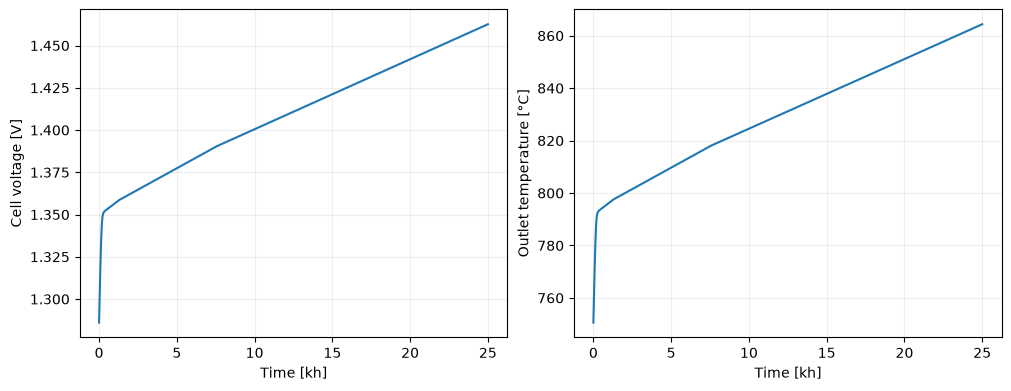

In [88]:
r = adiabatic
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
axes[0].plot(r["t"], r["voltage"])
axes[0].set(ylabel="Cell voltage [V]")
axes[1].plot(r["t"], r["T_out"] - 273.15)
axes[1].set(ylabel="Outlet temperature [°C]")

for ax in axes:
    ax.set_xlabel("Time [kh]")
    ax.grid(alpha=0.2)

## 7. Impedance of the degraded cell

The degraded state at any time can be used to calculate an impedance spectrum with the EIS model of nest-soc (see [3_eis.ipynb](3_eis.ipynb)). 

The degraded state at a given time is written into the layers:

* **Ni agglomeration**: the TPB density of the fuel electrode is the initial TPB length times the TPB ratio at that time (fuel electrode arc).
* **Ni migration** and **interconnect oxidation**: the Ni-depleted zone and oxide scale, with their thicknesses at that time, are added to the electrolyte layers (ohmic resistance).

The EIS model is isothermal, so the mean cell temperature at that time is used, with the cell-averaged degraded state. The spectrum is obtained from a small voltage step near open circuit, as in [3_eis.ipynb](3_eis.ipynb).

In [89]:
from nest.cell import ChannelGeometry
from nest.eis import Model, impedance, solve_steady, solve_transient, voltage_ramp


def eis_cell(time_h, result):
    # Cell-averaged degraded state and mean temperature at time_h [h]
    state = {
        key: np.interp(time_h / 1000, result["t"], result[key])
        for key in ("tpb_ratio", "depleted", "oxide", "T_mean")
    }
    fuel_delta, air_delta = 10e-6, 30e-6  # [m]
    air_tpb = 1.82e12  # [1/m^2]
    fuel = layers.Layer(
        delta=fuel_delta,
        kinetic=layers.ButlerVolmer(
            fuel_mix,
            nu=[-1, 1],
            n_e=2,
            alpha=0.782,
            beta=1 - 0.782,
            p=[-0.0467, 0.3905],
            theta=1,
            E_act=1.26e5,
            exchange_current_prefactor=8.546e6 / (tpb_0 * fuel_delta),
        ),
        transport=layers.PorousTransport(dp=6.41e-7, epsilon=EPSILON, tau=TAU),
        # Effective ionic conductivity: YSZ fraction 0.58*(1 - porosity), ionic tortuosity 2.8
        conductivity=layers.Conductivity(
            sigma0=3.6e7 * 0.58 * (1 - EPSILON) / 2.8, E_act=80e3, theta=-1
        ),
        tpb_density=tpb_0 * state["tpb_ratio"],  # Ni agglomeration
        capacitance_volumetric=6.76e5,  # [F/m^3]
    )
    air = layers.Layer(
        delta=air_delta,
        kinetic=layers.ButlerVolmer(
            air_mix,
            nu=[-0.5, 0.0],
            n_e=2,
            alpha=0.996,
            beta=1 - 0.996,
            p=[0.146, 0.0],
            theta=1,
            E_act=1.22e5,
            exchange_current_prefactor=2.593e8 / (air_tpb * air_delta),
        ),
        transport=layers.PorousTransport(dp=3.04e-7, epsilon=EPSILON, tau=TAU),
        # Effective ionic conductivity: CGO fraction 0.5*(1 - porosity), ionic tortuosity 1.8
        conductivity=layers.Conductivity(
            sigma0=1.09e7 * 0.5 * (1 - EPSILON) / 1.8, E_act=61.75e3, theta=-1
        ),
        tpb_density=air_tpb,
        capacitance_volumetric=5.89e7,  # [F/m^3]
    )
    # Lumped ohmic resistance T/B*exp(E/RT) of Ref. [1], without the electrodes.
    # The fitted lumped resistance of Ref. [1] (159 mOhm cm2 at 750 degC) includes the ionic
    # conduction in the electrodes, which the EIS model resolves itself (64 mOhm cm2 here).
    # B is increased by 1.675 so that the total ohmic resistance (high-frequency intercept)
    # matches the degradation model at the beginning of life.
    ohmic = layers.Layer(
        delta=1.0,
        conductivity=layers.Conductivity(
            sigma0=7.8247e11 * 1.675, E_act=8.0022e4, theta=-1
        ),
    )
    # Degraded layers with their thickness at time_h
    Ni_depleted = layers.Layer(  # Ni migration
        delta=state["depleted"],
        conductivity=layers.Conductivity(
            sigma0=3.6e7 * EPSILON / TAU, E_act=8e4, theta=-1
        ),
    )
    oxide_scale = layers.Layer(  # Interconnect oxidation
        delta=state["oxide"],
        conductivity=layers.Conductivity(sigma0=45.8, E_act=33.3e3, theta=0),
    )

    eis = cell.Cell(AREA, fuel, (Ni_depleted, ohmic, oxide_scale), air)
    eis.fuel_channel = ChannelGeometry(length=0.20, width=0.20, height=1.3e-3)
    eis.air_channel = ChannelGeometry(length=0.20, width=0.20, height=1.3e-3)
    eis.fuel_support = layers.Layer(
        delta=300e-6,
        transport=layers.PorousTransport(dp=6.41e-7, epsilon=EPSILON, tau=TAU),
    )
    return eis, state


def impedance_spectrum(eis, temperature, frequencies):
    model = Model(eis, inlet_conditions(temperature, j), n_x=10, n_zf=4, n_za=3, n_zs=2)
    ocv = model.voltage_for_current(model.initial_state())
    voltage_before = ocv + 50e-3
    steady = solve_steady(model, voltage_before)
    current_before = float(model.current_density(steady.x, voltage_before).mean())

    ramp = voltage_ramp(initial=voltage_before, final=ocv, tau=2e-7)
    times = np.r_[0.0, np.geomspace(1e-9, 30.0, 500)]
    transient = solve_transient(
        model,
        ramp,
        (0.0, times[-1]),
        initial_state=steady.x,
        t_eval=times,
        rtol=1e-6,
        atol=1e-8,
    )
    voltage = np.array([ramp(t) for t in transient.t])
    current = np.array(
        [model.current_density(y, v).mean() for y, v in zip(transient.y.T, voltage)]
    )
    return impedance(
        transient.t,
        voltage,
        current,
        frequencies,
        voltage_before=voltage_before,
        current_before=current_before,
    )

The impedance is calculated at the beginning of life, 300 h, 1000 h, 2000 h.

In [92]:
eis_times = [0, 100, 1000]  # [h]
frequencies = np.geomspace(0.1, 1e6, 120)  # [Hz]

spectra = {}
for time_h in eis_times:
    eis, state = eis_cell(time_h, adiabatic)
    Z = impedance_spectrum(eis, state["T_mean"], frequencies) * 1e4  # [ohm cm^2]
    spectra[time_h] = Z
    valid = np.isfinite(Z)

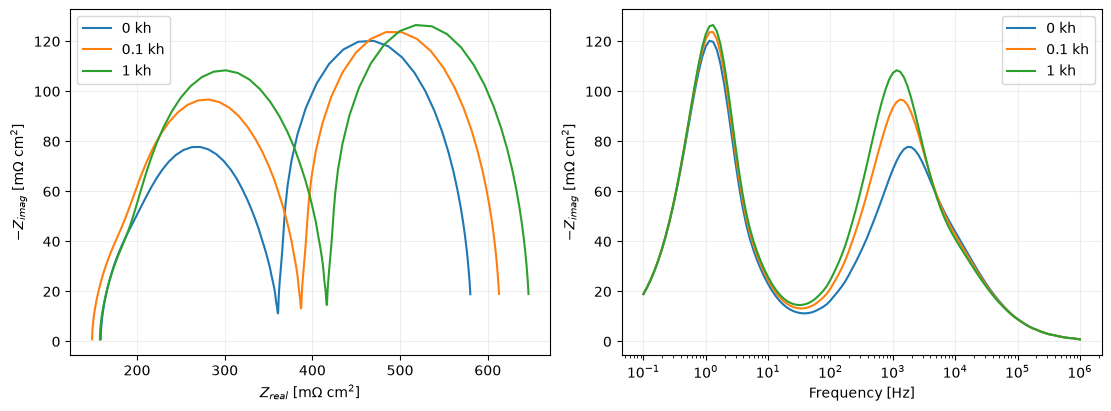

In [93]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for time_h, Z in spectra.items():
    valid = np.isfinite(Z)
    label = f"{time_h / 1000:g} kh"
    axes[0].plot(Z[valid].real * 1e3, -Z[valid].imag * 1e3, label=label)
    axes[1].semilogx(frequencies[valid], -Z[valid].imag * 1e3, label=label)
axes[0].set(
    xlabel=r"$Z_{real}$ [m$\Omega$ cm$^2$]", ylabel=r"$-Z_{imag}$ [m$\Omega$ cm$^2$]"
)
axes[1].set(xlabel="Frequency [Hz]", ylabel=r"$-Z_{imag}$ [m$\Omega$ cm$^2$]")
for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend()